In [2]:
from pathlib import Path

# Move one level up from notebooks to project root
PROJECT_ROOT = Path.cwd().parent

print("Project root:", PROJECT_ROOT)

# Define data file paths
ENCODED_FILE = (
    PROJECT_ROOT / "data" / "processed" / "encoded_sequences.csv"
)

SPLIT_FILE = (
    PROJECT_ROOT / "data" / "processed" / "split_assignments.csv"
)

print("\nFile verification:")
print("Encoded sequences:", ENCODED_FILE.exists())
print("Split assignments:", SPLIT_FILE.exists())

Project root: D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection

File verification:
Encoded sequences: True
Split assignments: True


In [3]:
import pandas as pd

split_df = pd.read_csv(
    SPLIT_FILE,
    usecols=["BlockId", "ActualLabel", "Dataset"]
)

print("Total records:", len(split_df))

print("\nDataset distribution:")
display(
    split_df.groupby(["Dataset", "ActualLabel"])
    .size()
    .reset_index(name="Total")
)

Total records: 575061

Dataset distribution:


,Dataset,ActualLabel,Total
0,Test,Anomaly,16838
1,Test,Normal,83828
2,Train,Normal,391043
3,Validation,Normal,83352


In [4]:
# Load encoded sequences
encoded_df = pd.read_csv(
    ENCODED_FILE,
    usecols=[
        "BlockId",
        "EncodedFeatures",
        "SequenceLength",
        "ActualLabel"
    ]
)

print("Total encoded records:", len(encoded_df))
print("\nDataset preview:")
display(encoded_df.head())

Total encoded records: 575061

Dataset preview:


,BlockId,EncodedFeatures,SequenceLength,ActualLabel
0,blk_7447720936221071962,"5,22,5,5,11,9,11,9,11,9,26,26,26,4,3,4,2,23,23...",23,Normal
1,blk_-2129076755500825500,"5,5,22,5,11,9,11,9,11,9,26,26,26,4,4,3,2,23,23...",23,Normal
2,blk_-9161574303807485051,"5,22,5,5,11,9,11,9,11,9,26,26,26,4,3,4,23,23,2...",22,Normal
3,blk_1085930350461885394,"5,5,22,5,11,9,11,11,9,9,26,26,26,4,3,4,23,23,2...",22,Normal
4,blk_1955612624060911018,"5,22,5,5,11,9,11,9,11,9,26,26,26,4,3,4,2,23,23...",23,Normal


In [5]:
# Join encoded sequences with split assignments
model_data = encoded_df.merge(
    split_df[["BlockId", "Dataset"]],
    on="BlockId",
    how="inner",
    validate="one_to_one"
)

print("Total joined records:", len(model_data))

print("\nDataset distribution:")
display(
    model_data.groupby(["Dataset", "ActualLabel"])
    .size()
    .reset_index(name="Total")
)

print("\nMissing dataset assignments:", model_data["Dataset"].isna().sum())

Total joined records: 575061

Dataset distribution:


,Dataset,ActualLabel,Total
0,Test,Anomaly,16838
1,Test,Normal,83828
2,Train,Normal,391043
3,Validation,Normal,83352



Missing dataset assignments: 0


In [6]:
# Separate training, validation and test data
train_df = model_data[
    model_data["Dataset"] == "Train"
].copy()

val_df = model_data[
    model_data["Dataset"] == "Validation"
].copy()

test_df = model_data[
    model_data["Dataset"] == "Test"
].copy()

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nTraining labels:")
print(train_df["ActualLabel"].value_counts())

print("\nValidation labels:")
print(val_df["ActualLabel"].value_counts())

print("\nTesting labels:")
print(test_df["ActualLabel"].value_counts())

Training records: 391043
Validation records: 83352
Testing records: 100666

Training labels:
ActualLabel
Normal    391043
Name: count, dtype: int64

Validation labels:
ActualLabel
Normal    83352
Name: count, dtype: int64

Testing labels:
ActualLabel
Normal     83828
Anomaly    16838
Name: count, dtype: int64


In [7]:
# Verify sequence parsing
def parse_sequence(sequence):
    return [int(event) for event in sequence.split(",")]

# Inspect three training sequences
for i in range(3):
    sequence = parse_sequence(
        train_df.iloc[i]["EncodedFeatures"]
    )

    print(f"\nSequence {i + 1}:")
    print("Events:", sequence)
    print("Parsed length:", len(sequence))
    print("Expected length:", train_df.iloc[i]["SequenceLength"])


Sequence 1:
Events: [5, 22, 5, 5, 11, 9, 11, 9, 11, 9, 26, 26, 26, 4, 3, 4, 2, 23, 23, 23, 21, 21, 21]
Parsed length: 23
Expected length: 23

Sequence 2:
Events: [5, 5, 22, 5, 11, 9, 11, 9, 11, 9, 26, 26, 26, 4, 4, 3, 2, 23, 23, 23, 21, 21, 21]
Parsed length: 23
Expected length: 23

Sequence 3:
Events: [5, 22, 5, 5, 11, 9, 11, 9, 11, 9, 26, 26, 26, 4, 3, 4, 23, 23, 23, 21, 21, 21]
Parsed length: 22
Expected length: 22


In [8]:
# Verify event ID boundaries
all_event_ids = set()

for sequence in train_df["EncodedFeatures"]:
    all_event_ids.update(parse_sequence(sequence))

print("Unique event IDs:", len(all_event_ids))
print("Minimum event ID:", min(all_event_ids))
print("Maximum event ID:", max(all_event_ids))
print("Event IDs:", sorted(all_event_ids))

print("\nVocabulary verification:",
      "PASSED" if all_event_ids == set(range(1, 30)) else "FAILED")

Unique event IDs: 17
Minimum event ID: 2
Maximum event ID: 28
Event IDs: [2, 3, 4, 5, 6, 9, 11, 16, 18, 20, 21, 22, 23, 25, 26, 27, 28]

Vocabulary verification: FAILED


In [10]:
# Verify the complete dataset
all_event_ids = set()

for sequence in encoded_df["EncodedFeatures"]:
    all_event_ids.update(parse_sequence(sequence))

print("Unique event IDs:", len(all_event_ids))
print("Minimum event ID:", min(all_event_ids))
print("Maximum event ID:", max(all_event_ids))
print("Event IDs:", sorted(all_event_ids))

print(
    "\nVocabulary verification:",
    "PASSED" if all_event_ids == set(range(1, 30)) else "FAILED"
)

Unique event IDs: 29
Minimum event ID: 1
Maximum event ID: 29
Event IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]

Vocabulary verification: PASSED


In [11]:
# Configure LSTM preparation parameters
# Event vocabulary configuration
VOCAB_SIZE = 30       # 29 events + padding index 0
PADDING_IDX = 0

# LSTM preparation configuration
EMBEDDING_DIM = 16
HIDDEN_DIM = 32
BATCH_SIZE = 32

# Reproducibility
RANDOM_SEED = 42

print("Vocabulary size:", VOCAB_SIZE)
print("Padding index:", PADDING_IDX)
print("Embedding dimension:", EMBEDDING_DIM)
print("LSTM hidden dimension:", HIDDEN_DIM)
print("Batch size:", BATCH_SIZE)
print("Random seed:", RANDOM_SEED)

Vocabulary size: 30
Padding index: 0
Embedding dimension: 16
LSTM hidden dimension: 32
Batch size: 32
Random seed: 42


In [3]:
# Create the event vocabulary configuration
# Event vocabulary configuration
VOCAB_SIZE = 30
PADDING_IDX = 0

# Model configuration
EMBEDDING_DIM = 16
HIDDEN_DIM = 32
BATCH_SIZE = 32

print("Vocabulary size:", VOCAB_SIZE)
print("Padding index:", PADDING_IDX)
print("Embedding dimension:", EMBEDDING_DIM)
print("Hidden dimension:", HIDDEN_DIM)
print("Batch size:", BATCH_SIZE)

Vocabulary size: 30
Padding index: 0
Embedding dimension: 16
Hidden dimension: 32
Batch size: 32


In [4]:
# Load the prepared datasets
import pandas as pd
from pathlib import Path

# Project directory
PROJECT_ROOT = Path.cwd().parent

# Dataset paths
ENCODED_FILE = PROJECT_ROOT / "data" / "processed" / "encoded_sequences.csv"
SPLIT_FILE = PROJECT_ROOT / "data" / "processed" / "split_assignments.csv"

# Load datasets
encoded_df = pd.read_csv(ENCODED_FILE)

split_df = pd.read_csv(SPLIT_FILE)

# Join using BlockId
model_data = encoded_df.merge(
    split_df[["BlockId", "Dataset"]],
    on="BlockId",
    how="inner",
    validate="one_to_one"
)

print("Total records:", len(model_data))
print("\nDataset distribution:")
print(model_data["Dataset"].value_counts())

print("\nMissing values:")
print(model_data.isnull().sum())

Total records: 575061

Dataset distribution:
Dataset
Train         391043
Test          100666
Validation     83352
Name: count, dtype: int64

Missing values:
BlockId            0
EncodedFeatures    0
SequenceLength     0
ActualLabel        0
Dataset            0
dtype: int64


In [36]:
from torch.utils.data import Dataset

class HDFSSequenceDataset(Dataset):

    def __init__(self, dataframe):
        self.sequences = dataframe["EncodedFeatures"].tolist()

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, index):
        sequence = self.sequences[index]

        event_ids = [int(x) for x in sequence.split(",")]

        return torch.tensor(event_ids, dtype=torch.long)

In [37]:
print("Dataset class created:", HDFSSequenceDataset)

Dataset class created: <class '__main__.HDFSSequenceDataset'>


In [40]:
# Separate datasets using existing split assignments

train_df = model_data[
    model_data["Dataset"] == "Train"
].copy()

val_df = model_data[
    model_data["Dataset"] == "Validation"
].copy()

test_df = model_data[
    model_data["Dataset"] == "Test"
].copy()

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

Training records: 391043
Validation records: 83352
Testing records: 100666


In [41]:
train_dataset = HDFSSequenceDataset(train_df)

print("Training dataset size:", len(train_dataset))

sample = train_dataset[0]

print("\nFirst sequence tensor:")
print(sample)

print("\nTensor shape:", sample.shape)
print("Tensor data type:", sample.dtype)

Training dataset size: 391043

First sequence tensor:
tensor([ 5, 22,  5,  5, 11,  9, 11,  9, 11,  9, 26, 26, 26,  4,  3,  4,  2, 23,
        23, 23, 21, 21, 21])

Tensor shape: torch.Size([23])
Tensor data type: torch.int64


In [55]:
# Create the padding function
from torch.nn.utils.rnn import pad_sequence

def collate_fn(batch):

    lengths = torch.tensor(
        [len(seq) for seq in batch],
        dtype=torch.long
    )

    padded_sequences = pad_sequence(
        batch,
        batch_first=True,
        padding_value=PADDING_IDX
    )

    return padded_sequences, lengths

In [43]:
# Test dynamic padding
sample_batch = [
    torch.tensor([5, 22, 11]),
    torch.tensor([3, 4, 2, 9, 8]),
    torch.tensor([7, 6])
]

padded_batch = collate_fn(sample_batch)

print("Padded batch:")
print(padded_batch)

print("\nBatch shape:", padded_batch.shape)

Padded batch:
tensor([[ 5, 22, 11,  0,  0],
        [ 3,  4,  2,  9,  8],
        [ 7,  6,  0,  0,  0]])

Batch shape: torch.Size([3, 5])


In [44]:
# Create the PyTorch DataLoader
# It retrieves individual sequences from the Dataset, groups them into batches, and applies our collate_fn to dynamically pad each batch.
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Batch size:", BATCH_SIZE)

Training batches: 12221
Batch size: 32


In [45]:
# Inspect an actual training batch
# verify what the DataLoader produces
# Get one batch from the training DataLoader
batch = next(iter(train_loader))

print("Batch shape:", batch.shape)
print("Batch data type:", batch.dtype)

print("\nFirst sequence in batch:")
print(batch[0])

print("\nPadding count in batch:", (batch == PADDING_IDX).sum().item())

Batch shape: torch.Size([32, 28])
Batch data type: torch.int64

First sequence in batch:
tensor([ 5,  5, 22,  5, 11,  9, 11,  9, 11,  9, 26, 26, 26,  2, 23, 23, 23, 21,
        21, 21,  0,  0,  0,  0,  0,  0,  0,  0])

Padding count in batch: 292


In [46]:
# Padding masks
sample_sequence = batch[0]

padding_mask = sample_sequence != PADDING_IDX

print("Sequence:")
print(sample_sequence)

print("\nPadding mask:")
print(padding_mask)

print("\nActual event positions:", padding_mask.sum().item())
print("Padding positions:", (~padding_mask).sum().item())

Sequence:
tensor([ 5,  5, 22,  5, 11,  9, 11,  9, 11,  9, 26, 26, 26,  2, 23, 23, 23, 21,
        21, 21,  0,  0,  0,  0,  0,  0,  0,  0])

Padding mask:
tensor([ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
        False, False, False, False, False, False, False, False])

Actual event positions: 20
Padding positions: 8


In [47]:
# Implement the reconstruction loss function
criterion = nn.CrossEntropyLoss(
    ignore_index=PADDING_IDX
)

print("Loss function:", criterion)

Loss function: CrossEntropyLoss()


In [48]:
# Implement the LSTM Encoder
# The Encoder reads an event sequence and learns a compressed representation of its patterns.
class LSTMEncoder(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super().__init__()

        # Convert event IDs into embedding vectors
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PADDING_IDX
        )

        # LSTM encoder
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

    def forward(self, x, lengths):

        # Convert event IDs into embeddings
        embedded = self.embedding(x)

        # Pack variable-length sequences to ignore padding
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # Extract final hidden and cell states
        _, (hidden, cell) = self.lstm(packed)

        return hidden, cell

In [53]:
# Implement the LSTM Decoder
class LSTMDecoder(nn.Module):

    def __init__(self, vocab_size, hidden_dim):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=hidden_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.output_layer = nn.Linear(
            hidden_dim,
            vocab_size
        )

    def forward(self, hidden, cell, max_len):

        context = hidden[-1].unsqueeze(1).expand(
            -1, max_len, -1
        )

        output, _ = self.lstm(
            context,
            (hidden, cell)
        )

        logits = self.output_layer(output)

        return logits

In [54]:
# Combine Encoder and Decoder into an Autoencoder
class LSTM_Autoencoder(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super().__init__()

        self.encoder = LSTMEncoder(
            vocab_size,
            embedding_dim,
            hidden_dim
        )

        self.decoder = LSTMDecoder(
            vocab_size,
            hidden_dim
        )

    def forward(self, x, lengths):

        hidden, cell = self.encoder(x, lengths)

        logits = self.decoder(
            hidden,
            cell,
            x.size(1)
        )

        return logits

In [51]:
# Initialize the LSTM Autoencoder
# Defining a class creates the architecture blueprint. Initializing the model creates the actual neural network layers and their trainable parameters.
model = LSTM_Autoencoder(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM
).to(DEVICE)

print(model)

LSTM_Autoencoder(
  (encoder): LSTMEncoder(
    (embedding): Embedding(30, 16, padding_idx=0)
    (lstm): LSTM(16, 32, batch_first=True)
  )
  (decoder): LSTMDecoder(
    (embedding): Embedding(30, 16, padding_idx=0)
    (lstm): LSTM(16, 32, batch_first=True)
    (output_layer): Linear(in_features=32, out_features=30, bias=True)
  )
)


In [57]:
# Verify Sequence Lengths
sample_batch = [
    torch.tensor([5, 22, 11]),
    torch.tensor([3, 4, 2, 9, 8]),
    torch.tensor([7, 6])
]

padded, lengths = collate_fn(sample_batch)

print("Padded shape:", padded.shape)
print("Original sequence lengths:", lengths)

Padded shape: torch.Size([3, 5])
Original sequence lengths: tensor([3, 5, 2])


In [58]:
# Recreate the training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0
)

print("Training batches:", len(train_loader))

Training batches: 12221


In [59]:
# Initialize the corrected model
model = LSTM_Autoencoder(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM
).to(DEVICE)

print(model)

LSTM_Autoencoder(
  (encoder): LSTMEncoder(
    (embedding): Embedding(30, 16, padding_idx=0)
    (lstm): LSTM(16, 32, batch_first=True)
  )
  (decoder): LSTMDecoder(
    (lstm): LSTM(32, 32, batch_first=True)
    (output_layer): Linear(in_features=32, out_features=30, bias=True)
  )
)


In [60]:
# Prepare a real training batch
# Objective: Get one actual batch from the training dataset and prepare it for the LSTM Autoencoder.
batch, lengths = next(iter(train_loader))

batch = batch.to(DEVICE)
lengths = lengths.to(DEVICE)

print("Batch shape:", batch.shape)
print("Lengths shape:", lengths.shape)
print("First 5 sequence lengths:", lengths[:5])
print("Device:", batch.device)

Batch shape: torch.Size([32, 31])
Lengths shape: torch.Size([32])
First 5 sequence lengths: tensor([19, 22, 19, 13, 19])
Device: cpu


In [61]:
# Run the model forward pass
# We'll pass the real batch through the LSTM Autoencoder.
model.eval()

with torch.no_grad():

    logits = model(batch, lengths)

print("Input shape:", batch.shape)
print("Model output shape:", logits.shape)
print("Output data type:", logits.dtype)

Input shape: torch.Size([32, 31])
Model output shape: torch.Size([32, 31, 30])
Output data type: torch.float32


In [62]:
# Configure the optimizer
# Now we'll prepare the optimizer that updates model weights during training.
# We'll use Adam optimizer with a learning rate of 0.001.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Optimizer:", optimizer)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.001


In [63]:
# Calculate reconstruction loss

loss = criterion(
    logits.reshape(-1, VOCAB_SIZE),
    batch.reshape(-1)
)

print("Reconstruction loss:", loss.item())

Reconstruction loss: 3.391282081604004


In [64]:
# Train the model on one batch
model.train()

optimizer.zero_grad()

logits = model(batch, lengths)

loss = criterion(
    logits.reshape(-1, VOCAB_SIZE),
    batch.reshape(-1)
)

loss.backward()

optimizer.step()

print("Training loss:", loss.item())
print("One training batch completed successfully.")

Training loss: 3.391282320022583
One training batch completed successfully.


In [65]:
# Prepare a reusable training function
def train_one_epoch(model, loader, optimizer, criterion, device, max_batches=None):

    model.train()

    total_loss = 0.0
    batches_processed = 0

    for batch_idx, (sequences, lengths) in enumerate(loader):

        if max_batches is not None and batch_idx >= max_batches:
            break

        sequences = sequences.to(device)
        lengths = lengths.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(sequences, lengths)

        loss = criterion(
            logits.reshape(-1, VOCAB_SIZE),
            sequences.reshape(-1)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()
        batches_processed += 1

    average_loss = total_loss / batches_processed

    return average_loss

In [66]:
# Run a small training experiment
sample_train_loss = train_one_epoch(
    model=model,
    loader=train_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=DEVICE,
    max_batches=100
)

print("Batches trained: 100")
print("Average training loss:", sample_train_loss)

Batches trained: 100
Average training loss: 2.260606243610382


In [67]:
# Prepare a validation function
def evaluate_one_epoch(model, loader, criterion, device, max_batches=None):

    model.eval()

    total_loss = 0.0
    batches_processed = 0

    with torch.no_grad():

        for batch_idx, (sequences, lengths) in enumerate(loader):

            if max_batches is not None and batch_idx >= max_batches:
                break

            sequences = sequences.to(device)
            lengths = lengths.to(device)

            logits = model(sequences, lengths)

            loss = criterion(
                logits.reshape(-1, VOCAB_SIZE),
                sequences.reshape(-1)
            )

            total_loss += loss.item()
            batches_processed += 1

    return total_loss / batches_processed

In [69]:
# Create the validation DataLoader
val_dataset = HDFSSequenceDataset(val_df)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

print("Validation dataset size:", len(val_dataset))
print("Validation batches:", len(val_loader))

Validation dataset size: 83352
Validation batches: 2605


In [71]:
# Evaluate on 100 validation batchessample_val_loss = evaluate_one_epoch(
    model=model,
    loader=val_loader,
    criterion=criterion,
    device=DEVICE,
    max_batches=100
)

print("Validation batches: 100")
print("Average validation loss:", sample_val_loss)

Validation batches: 100
Average validation loss: 1.8410894668102264


In [72]:
# Measure training loss after the updates
final_train_loss = evaluate_one_epoch(
    model=model,
    loader=train_loader,
    criterion=criterion,
    device=DEVICE,
    max_batches=100
)

print("Training evaluation batches: 100")
print("Training evaluation loss:", final_train_loss)

Training evaluation batches: 100
Training evaluation loss: 1.5931503391265869


In [73]:
# Extend the pilot training
extended_train_loss = train_one_epoch(
    model=model,
    loader=train_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=DEVICE,
    max_batches=500
)

print("Additional training batches: 500")
print("Average training loss:", extended_train_loss)

Additional training batches: 500
Average training loss: 1.0943168002367019


In [74]:
# Re-evaluate training loss
train_loss_after_500 = evaluate_one_epoch(
    model=model,
    loader=train_loader,
    criterion=criterion,
    device=DEVICE,
    max_batches=100
)

print("Training evaluation loss:", train_loss_after_500)

Training evaluation loss: 0.8025187736749649


In [75]:
# Re-evaluate validation loss
val_loss_after_500 = evaluate_one_epoch(
    model=model,
    loader=val_loader,
    criterion=criterion,
    device=DEVICE,
    max_batches=100
)

print("Validation evaluation loss:", val_loss_after_500)

Validation evaluation loss: 1.0891652595996857


In [76]:
# Record our experiment results
experiment_results = {
    "training_batches": 600,
    "training_loss": 0.8025187736749649,
    "validation_loss": 1.0891652595996857,
    "batch_size": BATCH_SIZE,
    "embedding_dim": EMBEDDING_DIM,
    "hidden_dim": HIDDEN_DIM,
    "learning_rate": 0.001
}

for key, value in experiment_results.items():
    print(f"{key}: {value}")

training_batches: 600
training_loss: 0.8025187736749649
validation_loss: 1.0891652595996857
batch_size: 32
embedding_dim: 16
hidden_dim: 32
learning_rate: 0.001


In [77]:
# Save the pilot model
from pathlib import Path

model_path = PROJECT_ROOT / "models" / "lstm_autoencoder_pilot.pth"

model_path.parent.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "vocab_size": VOCAB_SIZE,
        "embedding_dim": EMBEDDING_DIM,
        "hidden_dim": HIDDEN_DIM,
        "padding_idx": PADDING_IDX,
        "training_batches": 600,
        "training_loss": 0.8025187736749649,
        "validation_loss": 1.0891652595996857
    },
    model_path
)

print("Pilot model saved successfully!")
print("Saved location:", model_path)

Pilot model saved successfully!
Saved location: D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection\models\lstm_autoencoder_pilot.pth


In [78]:
# Continue training experiment
extended_train_loss_2 = train_one_epoch(
    model=model,
    loader=train_loader,
    optimizer=optimizer,
    criterion=criterion,
    device=DEVICE,
    max_batches=1000
)

print("Additional training batches: 1000")
print("Average training loss:", extended_train_loss_2)

Additional training batches: 1000
Average training loss: 0.6066469542086125


In [79]:
# Evaluate training loss
train_loss_after_1600 = evaluate_one_epoch(
    model=model,
    loader=train_loader,
    criterion=criterion,
    device=DEVICE,
    max_batches=100
)

print("Training evaluation loss:", train_loss_after_1600)

Training evaluation loss: 0.4701028084754944


In [81]:
# Evaluate validation loss
val_loss_after_1600 = evaluate_one_epoch(
    model=model,
    loader=val_loader,
    criterion=criterion,
    device=DEVICE,
    max_batches=100
)

print("Validation evaluation loss:", val_loss_after_1600)

Validation evaluation loss: 0.6349170765280724


In [82]:
# Save the improved model
improved_model_path = (
    PROJECT_ROOT / "models" / "lstm_autoencoder_improved.pth"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "vocab_size": VOCAB_SIZE,
        "embedding_dim": EMBEDDING_DIM,
        "hidden_dim": HIDDEN_DIM,
        "padding_idx": PADDING_IDX,
        "training_batches": 1600,
        "training_loss": train_loss_after_1600,
        "validation_loss": val_loss_after_1600
    },
    improved_model_path
)

print("Improved model saved successfully!")
print("Location:", improved_model_path)

Improved model saved successfully!
Location: D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection\models\lstm_autoencoder_improved.pth


In [83]:
# Create the test DataLoader
test_dataset = HDFSSequenceDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

print("Test dataset size:", len(test_dataset))
print("Test batches:", len(test_loader))

Test dataset size: 100666
Test batches: 3146


In [84]:
# Verify test labels
print("Test label distribution:")
print(test_df["ActualLabel"].value_counts())

print("\nTest label percentages:")
print(
    test_df["ActualLabel"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Test label distribution:
ActualLabel
Normal     83828
Anomaly    16838
Name: count, dtype: int64

Test label percentages:
ActualLabel
Normal     83.27
Anomaly    16.73
Name: proportion, dtype: float64


In [85]:
# Calculate reconstruction scores
import numpy as np

def calculate_reconstruction_scores(
    model, loader, criterion, device
):

    model.eval()
    all_scores = []

    with torch.no_grad():

        for sequences, lengths in loader:

            sequences = sequences.to(device)
            lengths = lengths.to(device)

            logits = model(sequences, lengths)

            token_losses = torch.nn.functional.cross_entropy(
                logits.transpose(1, 2),
                sequences,
                ignore_index=PADDING_IDX,
                reduction="none"
            )

            sequence_scores = (
                token_losses.sum(dim=1) / lengths
            )

            all_scores.extend(
                sequence_scores.cpu().numpy()
            )

    return np.array(all_scores)

In [86]:
# Calculate test reconstruction scores
test_scores = calculate_reconstruction_scores(
    model=model,
    loader=test_loader,
    criterion=criterion,
    device=DEVICE
)

print("Total test scores:", len(test_scores))
print("Minimum score:", test_scores.min())
print("Maximum score:", test_scores.max())
print("Mean score:", test_scores.mean())
print("First 10 scores:", test_scores[:10])

Total test scores: 100666
Minimum score: 0.21427572
Maximum score: 7.1887608
Mean score: 0.7826855
First 10 scores: [0.5032486  1.3834624  0.47750434 0.56360644 0.48641732 0.47750434
 0.43362948 0.8536864  0.91756004 0.47820395]


In [87]:
# Compare normal and anomalous reconstruction scores
test_results = test_df.copy()

test_results["ReconstructionScore"] = test_scores

print(
    test_results.groupby("ActualLabel")[
        "ReconstructionScore"
    ].describe().round(4)
)

               count    mean     std     min     25%     50%     75%     max
ActualLabel                                                                 
Anomaly      16838.0  2.4948  1.3554  0.7369  1.1738  2.4959  3.5322  7.1888
Normal       83828.0  0.4388  0.2580  0.2143  0.2585  0.3497  0.5737  5.7776


In [88]:
# Calculate validation reconstruction scores
val_scores = calculate_reconstruction_scores(
    model=model,
    loader=val_loader,
    criterion=criterion,
    device=DEVICE
)

print("Total validation scores:", len(val_scores))
print("Minimum:", val_scores.min())
print("Maximum:", val_scores.max())
print("Mean:", val_scores.mean())
print("Median:", np.median(val_scores))

Total validation scores: 83352
Minimum: 0.21427572
Maximum: 5.9155383
Mean: 0.4383996
Median: 0.34970066


In [90]:
# Calculate candidate anomaly thresholds
thresholds = {
    "95th_percentile": np.percentile(val_scores, 95),
    "97.5th_percentile": np.percentile(val_scores, 97.5),
    "99th_percentile": np.percentile(val_scores, 99)
}

for name, threshold in thresholds.items():
    print(f"{name}: {threshold:.4f}")

95th_percentile: 0.8074
97.5th_percentile: 0.8838
99th_percentile: 1.0262


In [91]:
# Evaluate all three thresholds
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_true = (
    test_results["ActualLabel"] == "Anomaly"
).astype(int)

for name, threshold in thresholds.items():

    y_pred = (
        test_results["ReconstructionScore"] > threshold
    ).astype(int)

    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred
    ).ravel()

    print(f"\n{name}")
    print(f"Threshold: {threshold:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")


95th_percentile
Threshold: 0.8074
Precision: 0.8004
Recall: 0.9703
F1-score: 0.8772
TN: 79754, FP: 4074, FN: 500, TP: 16338

97.5th_percentile
Threshold: 0.8838
Precision: 0.8823
Recall: 0.9241
F1-score: 0.9027
TN: 81753, FP: 2075, FN: 1278, TP: 15560

99th_percentile
Threshold: 1.0262
Precision: 0.9385
Recall: 0.8191
F1-score: 0.8747
TN: 82924, FP: 904, FN: 3046, TP: 13792


In [93]:
# Record the evaluation results
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix

evaluation_records = []

for name, threshold in thresholds.items():

    y_pred = (
        test_results["ReconstructionScore"] > threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred
    ).ravel()

    evaluation_records.append({
        "Threshold_Method": name,
        "Threshold": threshold,
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1_Score": f1_score(y_true, y_pred),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

lstm_evaluation_df = pd.DataFrame(evaluation_records)

print(lstm_evaluation_df.round(4))

    Threshold_Method  Threshold  Precision  Recall  F1_Score     TN    FP  \
0    95th_percentile     0.8074     0.8004  0.9703    0.8772  79754  4074   
1  97.5th_percentile     0.8838     0.8823  0.9241    0.9027  81753  2075   
2    99th_percentile     1.0262     0.9385  0.8191    0.8747  82924   904   

     FN     TP  
0   500  16338  
1  1278  15560  
2  3046  13792  


In [94]:
# Save the evaluation results
evaluation_path = (
    PROJECT_ROOT / "outputs" / "lstm_threshold_evaluation.csv"
)

evaluation_path.parent.mkdir(parents=True, exist_ok=True)

lstm_evaluation_df.to_csv(
    evaluation_path,
    index=False
)

print("Evaluation results saved successfully!")
print("Location:", evaluation_path)

Evaluation results saved successfully!
Location: D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection\outputs\lstm_threshold_evaluation.csv


In [95]:
# Save the latest trained model
final_model_path = (
    PROJECT_ROOT / "models" / "lstm_autoencoder_final.pth"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "vocab_size": VOCAB_SIZE,
        "embedding_dim": EMBEDDING_DIM,
        "hidden_dim": HIDDEN_DIM,
        "padding_idx": PADDING_IDX,
        "learning_rate": 0.001,
        "training_updates": 2601,
        "training_loss": train_loss_after_1600,
        "validation_loss": val_loss_after_1600,
        "thresholds": thresholds
    },
    final_model_path
)

print("Latest model saved successfully!")
print("Location:", final_model_path)

Latest model saved successfully!
Location: D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection\models\lstm_autoencoder_final.pth


In [96]:
# Correct checkpoint metadata
checkpoint = torch.load(
    final_model_path,
    map_location=DEVICE,
    weights_only=False
)

checkpoint["training_updates"] = 1601

torch.save(checkpoint, final_model_path)

print("Training update count corrected:", checkpoint["training_updates"])

Training update count corrected: 1601


In [97]:
# Verify the saved model checkpoint
# Load the saved checkpoint
checkpoint = torch.load(
    final_model_path,
    map_location=DEVICE,
    weights_only=False
)

# Create a fresh model using the saved configuration
reloaded_model = LSTM_Autoencoder(
    vocab_size=checkpoint["vocab_size"],
    embedding_dim=checkpoint["embedding_dim"],
    hidden_dim=checkpoint["hidden_dim"]
).to(DEVICE)

# Load trained weights
reloaded_model.load_state_dict(checkpoint["model_state_dict"])
reloaded_model.eval()

# Compare predictions from original and reloaded models
model.eval()

with torch.no_grad():
    original_output = model(batch, lengths)
    reloaded_output = reloaded_model(batch, lengths)

max_difference = torch.max(
    torch.abs(original_output - reloaded_output)
).item()

print("Checkpoint loaded successfully!")
print("Training updates:", checkpoint["training_updates"])
print("Original output shape:", original_output.shape)
print("Reloaded output shape:", reloaded_output.shape)
print("Maximum prediction difference:", max_difference)

Checkpoint loaded successfully!
Training updates: 1601
Original output shape: torch.Size([32, 31, 30])
Reloaded output shape: torch.Size([32, 31, 30])
Maximum prediction difference: 0.0


In [99]:
# Extract actual labels from the test dataframe
test_labels = test_df["ActualLabel"].values

# Verify alignment
print("Test scores:", len(test_scores))
print("Test labels:", len(test_labels))
print("\nLabel distribution:")
print(test_df["ActualLabel"].value_counts())

Test scores: 100666
Test labels: 100666

Label distribution:
ActualLabel
Normal     83828
Anomaly    16838
Name: count, dtype: int64


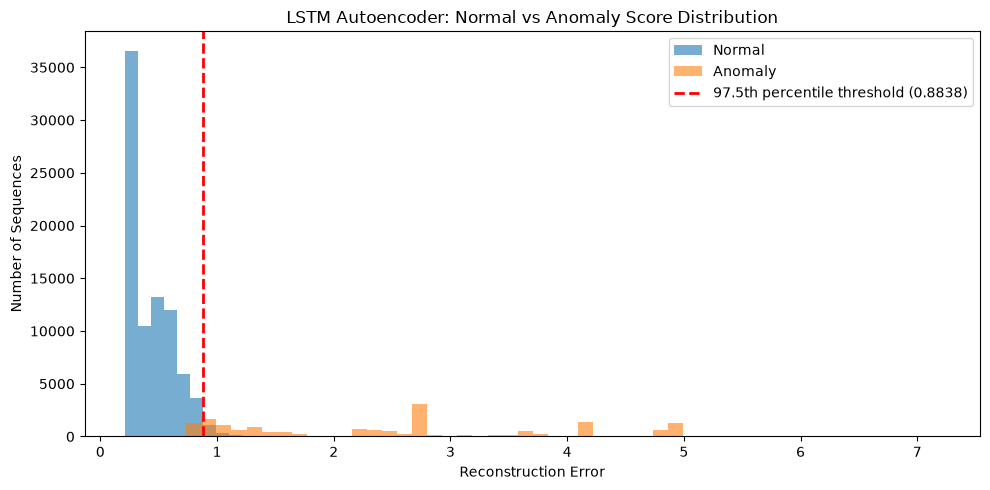

In [102]:
# Visualize normal vs anomaly scores
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    test_scores[test_labels == "Normal"],
    bins=50,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    test_scores[test_labels == "Anomaly"],
    bins=50,
    alpha=0.6,
    label="Anomaly"
)

plt.axvline(
    thresholds["97.5th_percentile"],
    color="red",
    linestyle="--",
    linewidth=2,
    label="97.5th percentile threshold (0.8838)"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Sequences")
plt.title("LSTM Autoencoder: Normal vs Anomaly Score Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [104]:
# checked this for above cell rror
print("Threshold dictionary:")
print(thresholds)

print("\nAvailable threshold keys:")
print(thresholds.keys())

Threshold dictionary:
{'95th_percentile': np.float32(0.80743366), '97.5th_percentile': np.float32(0.88377607), '99th_percentile': np.float32(1.0262055)}

Available threshold keys:
dict_keys(['95th_percentile', '97.5th_percentile', '99th_percentile'])


In [103]:
# Calculate ROC-AUC and PR-AUC
from sklearn.metrics import roc_auc_score, average_precision_score

# Convert labels into binary values
y_true = (test_labels == "Anomaly").astype(int)

# Calculate ranking metrics using continuous reconstruction scores
roc_auc = roc_auc_score(y_true, test_scores)

pr_auc = average_precision_score(y_true, test_scores)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC:  {pr_auc:.4f}")

ROC-AUC: 0.9924
PR-AUC:  0.9579


In [106]:
# Create the output directory and save
from pathlib import Path

# Create outputs directory if it does not exist
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save evaluation summary
output_path = output_dir / "lstm_model_evaluation_summary.csv"

lstm_summary.to_csv(output_path, index=False)

print(lstm_summary.to_string(index=False))
print("\nEvaluation summary saved successfully!")
print("Saved location:", output_path.resolve())

           Model  ROC_AUC   PR_AUC  Precision  Recall  F1_Score  Threshold
LSTM Autoencoder 0.992409 0.957942     0.8823  0.9241    0.9027   0.883776

Evaluation summary saved successfully!
Saved location: D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection\notebooks\outputs\lstm_model_evaluation_summary.csv


In [108]:
import pandas as pd
from pathlib import Path

# Load the saved split manifest
project_root = Path.cwd().parent

split_df = pd.read_csv(
    project_root / "data" / "processed" / "split_assignments.csv"
)

# Extract test records
test_split = split_df[
    split_df["Dataset"] == "Test"
].copy()

# Convert labels to binary format
y_test = (
    test_split["ActualLabel"]
    .map({"Normal": 0, "Anomaly": 1})
    .to_numpy()
)

print("Test records:", len(y_test))
print("Normal records:", (y_test == 0).sum())
print("Anomaly records:", (y_test == 1).sum())

Test records: 100666
Normal records: 83828
Anomaly records: 16838


In [109]:
# Reload the LSTM reconstruction scores
print("Test scores available:", "test_scores" in globals())
print("Selected threshold available:", "threshold_97_5" in globals())

Test scores available: True
Selected threshold available: False


In [110]:
# Restore the previously selected LSTM threshold
threshold_97_5 = 0.88377607

# Verify
print("LSTM threshold:", threshold_97_5)
print("Test scores:", len(test_scores))
print("Test labels:", len(y_test))

LSTM threshold: 0.88377607
Test scores: 100666
Test labels: 100666


In [111]:
# Create the incident detection dataset
import numpy as np
import pandas as pd

# Load encoded sequence records
encoded_df = pd.read_csv(
    project_root / "data" / "processed" / "encoded_sequences.csv"
)

# Extract test records using the saved split manifest
test_block_ids = test_split["BlockId"].reset_index(drop=True)

# Create incident detection dataframe
incident_df = pd.DataFrame({
    "BlockId": test_block_ids,
    "ReconstructionScore": test_scores,
    "PredictedAnomaly": (
        test_scores >= threshold_97_5
    ).astype(int)
})

# Add the original event sequences for investigation
incident_df = incident_df.merge(
    encoded_df[["BlockId", "EncodedFeatures", "SequenceLength"]],
    on="BlockId",
    how="left",
    validate="one_to_one"
)

print("Incident dataset shape:", incident_df.shape)
print("\nPrediction distribution:")
print(incident_df["PredictedAnomaly"].value_counts())

print("\nSample records:")
display(incident_df.head())

Incident dataset shape: (100666, 5)

Prediction distribution:
PredictedAnomaly
0    83031
1    17635
Name: count, dtype: int64

Sample records:


,BlockId,ReconstructionScore,PredictedAnomaly,EncodedFeatures,SequenceLength
0,blk_1085930350461885394,0.503249,0,"5,5,22,5,11,9,11,11,9,9,26,26,26,4,3,4,23,23,2...",22
1,blk_5643631875592041420,1.383462,1,"5,5,22,5,11,9,11,9,27,26,26,11,9,26,4,3,4,2,23...",24
2,blk_4152002788611889393,0.477504,0,"5,22,5,5,11,9,11,9,11,9,26,26,26,4,4,3,23,23,2...",22
3,blk_3261772386432516044,0.563606,0,"22,5,5,5,11,9,11,9,11,9,26,26,26,4,3,4,2,23,23...",23
4,blk_6367181725940135161,0.486417,0,"5,5,5,22,11,9,11,9,11,9,26,26,26,4,3,4,2,23,23...",23


In [112]:
# Examine reconstruction scores of detected anomalies

detected_incidents = incident_df[
    incident_df["PredictedAnomaly"] == 1
]

print("Detected incident score statistics:")
display(
    detected_incidents["ReconstructionScore"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame()
)

Detected incident score statistics:


,ReconstructionScore
count,17635.000000
mean,2.478816
std,1.333203
min,0.883897
25%,1.159611
50%,2.436367
75%,3.399400
90%,4.797725
95%,4.978459
99%,4.978459


In [113]:
# Calculate severity boundaries from detected incidents

severity_q25 = detected_incidents["ReconstructionScore"].quantile(0.25)
severity_q75 = detected_incidents["ReconstructionScore"].quantile(0.75)
severity_q90 = detected_incidents["ReconstructionScore"].quantile(0.90)

print("Incident severity boundaries")
print("--------------------------------")
print(f"Low / Medium boundary: {severity_q25:.4f}")
print(f"Medium / High boundary: {severity_q75:.4f}")
print(f"High / Critical boundary: {severity_q90:.4f}")

Incident severity boundaries
--------------------------------
Low / Medium boundary: 1.1596
Medium / High boundary: 3.3994
High / Critical boundary: 4.7977


In [114]:
# Assign severity to detected incidents

detected_incidents = detected_incidents.copy()

detected_incidents["Severity"] = pd.cut(
    detected_incidents["ReconstructionScore"],
    bins=[
        -np.inf,
        severity_q25,
        severity_q75,
        severity_q90,
        np.inf
    ],
    labels=["Low", "Medium", "High", "Critical"],
    right=False
)

print("Incident severity distribution:")
display(
    detected_incidents["Severity"]
    .value_counts()
    .reindex(["Low", "Medium", "High", "Critical"])
    .to_frame("Incident_Count")
)

Incident severity distribution:


,Incident_Count
Severity,
Low,4404
Medium,8822
High,2461
Critical,1948


In [115]:
# Find the 10 most unusual detected incidents

top_10_incidents = (
    detected_incidents
    .sort_values(
        by="ReconstructionScore",
        ascending=False
    )
    .head(10)
)

display(
    top_10_incidents[
        [
            "BlockId",
            "ReconstructionScore",
            "Severity",
            "SequenceLength",
            "EncodedFeatures"
        ]
    ]
)

,BlockId,ReconstructionScore,Severity,SequenceLength,EncodedFeatures
87698,blk_8006271611835981128,7.188761,Critical,49,"5,5,5,22,5,11,10,14,7,8,11,15,5,11,9,26,14,7,1..."
88124,blk_-6363674043695218814,7.155279,Critical,57,"22,5,5,5,12,14,5,7,11,10,11,10,14,7,8,11,15,5,..."
65096,blk_9099447004863711723,7.067800,Critical,13,"5,5,22,7,14,7,11,10,14,5,7,8,11"
88446,blk_-2448583810301041956,6.993265,Critical,44,"5,5,5,22,12,14,7,11,10,5,14,7,11,10,14,7,8,11,..."
88240,blk_-6994808880344424033,6.913114,Critical,40,"5,5,5,22,11,10,11,10,12,14,7,5,14,7,8,11,5,12,..."
88167,blk_8895996987918469659,6.882379,Critical,45,"5,5,22,5,12,14,7,11,10,15,5,12,14,7,11,10,14,7..."
88087,blk_7160764053931337311,6.881114,Critical,39,"5,22,5,5,10,14,7,11,10,5,14,7,8,11,11,15,15,5,..."
98154,blk_-2308563252795628677,6.838933,Critical,13,"5,5,22,7,11,10,14,5,7,8,11,14,7"
85434,blk_-6059290274455367169,6.831985,Critical,39,"5,5,22,5,14,7,11,10,15,5,12,14,7,11,10,14,7,8,..."
91103,blk_2832388045942608634,6.796925,Critical,39,"5,5,5,22,12,14,7,11,10,5,14,7,11,10,14,11,10,7..."


In [116]:
# Investigate the actual event patterns
# Inspect the event ID mapping

print("Event mapping available:", "event_to_id" in globals())

if "event_to_id" in globals():
    print("\nEvent-to-integer mapping:")
    for event, encoded_id in event_to_id.items():
        print(f"{encoded_id} -> {event}")

Event mapping available: False


In [117]:
# Restore event-to-integer mapping

event_to_id = {
    f"E{i}": i
    for i in range(1, 30)
}

# Create reverse mapping
id_to_event = {
    encoded_id: event
    for event, encoded_id in event_to_id.items()
}

print("Total event types:", len(event_to_id))
print("\nEncoded ID -> Original Event ID")

for encoded_id, event in id_to_event.items():
    print(f"{encoded_id} -> {event}")

Total event types: 29

Encoded ID -> Original Event ID
1 -> E1
2 -> E2
3 -> E3
4 -> E4
5 -> E5
6 -> E6
7 -> E7
8 -> E8
9 -> E9
10 -> E10
11 -> E11
12 -> E12
13 -> E13
14 -> E14
15 -> E15
16 -> E16
17 -> E17
18 -> E18
19 -> E19
20 -> E20
21 -> E21
22 -> E22
23 -> E23
24 -> E24
25 -> E25
26 -> E26
27 -> E27
28 -> E28
29 -> E29


In [118]:
# Select the highest-scoring incident
critical_block = top_10_incidents.iloc[0]

# Decode its event sequence
encoded_sequence = critical_block["EncodedFeatures"]

decoded_sequence = [
    id_to_event[int(event_id)]
    for event_id in encoded_sequence.split(",")
]

print("Block ID:", critical_block["BlockId"])
print("Anomaly score:", critical_block["ReconstructionScore"])
print("Severity:", critical_block["Severity"])
print("Sequence length:", critical_block["SequenceLength"])

print("\nDecoded HDFS event sequence:")
print(" -> ".join(decoded_sequence))

Block ID: blk_8006271611835981128
Anomaly score: 7.1887608
Severity: Critical
Sequence length: 49

Decoded HDFS event sequence:
E5 -> E5 -> E5 -> E22 -> E5 -> E11 -> E10 -> E14 -> E7 -> E8 -> E11 -> E15 -> E5 -> E11 -> E9 -> E26 -> E14 -> E7 -> E11 -> E10 -> E12 -> E14 -> E7 -> E5 -> E19 -> E14 -> E7 -> E11 -> E10 -> E14 -> E7 -> E8 -> E11 -> E25 -> E18 -> E5 -> E5 -> E6 -> E16 -> E6 -> E26 -> E26 -> E23 -> E23 -> E23 -> E21 -> E21 -> E21 -> E20


In [119]:
# Connect event IDs to HDFS log templates
# Locate the original HDFS log templates file

template_files = list(
    project_root.rglob("HDFS.log_templates.csv")
)

print("Matching files found:", len(template_files))

for file in template_files:
    print(file)

Matching files found: 1
D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection\data\extracted\preprocessed\HDFS.log_templates.csv


In [120]:
# Load HDFS event templates

template_path = template_files[0]

templates_df = pd.read_csv(template_path)

print("Template dataset shape:", templates_df.shape)

print("\nColumn names:")
print(templates_df.columns.tolist())

print("\nFirst 10 records:")
display(templates_df.head(10))

Template dataset shape: (29, 2)

Column names:
['EventId', 'EventTemplate']

First 10 records:


,EventId,EventTemplate
0,E1,[*]Adding an already existing block[*]
1,E2,[*]Verification succeeded for[*]
2,E3,[*]Served block[*]to[*]
3,E4,[*]Got exception while serving[*]to[*]
4,E5,[*]Receiving block[*]src:[*]dest:[*]
5,E6,[*]Received block[*]src:[*]dest:[*]of size[*]
6,E7,[*]writeBlock[*]received exception[*]
7,E8,[*]PacketResponder[*]for block[*]Interrupted[*]
8,E9,[*]Received block[*]of size[*]from[*]
9,E10,[*]PacketResponder[*]Exception[*]


In [121]:
# Decode the critical incident into actual log descriptions
# Create event ID to log-template mapping

event_template_map = dict(
    zip(
        templates_df["EventId"],
        templates_df["EventTemplate"]
    )
)

# Convert event IDs into log-template descriptions
critical_event_templates = [
    event_template_map[event]
    for event in decoded_sequence
]

print("Critical Block:", critical_block["BlockId"])
print("\nOriginal HDFS log templates:\n")

for i, (event, template) in enumerate(
    zip(decoded_sequence, critical_event_templates),
    start=1
):
    print(f"{i:02d}. {event}: {template}")

Critical Block: blk_8006271611835981128

Original HDFS log templates:

01. E5: [*]Receiving block[*]src:[*]dest:[*]
02. E5: [*]Receiving block[*]src:[*]dest:[*]
03. E5: [*]Receiving block[*]src:[*]dest:[*]
04. E22: [*]BLOCK* NameSystem[*]allocateBlock:[*]
05. E5: [*]Receiving block[*]src:[*]dest:[*]
06. E11: [*]PacketResponder[*]for block[*]terminating[*]
07. E10: [*]PacketResponder[*]Exception[*]
08. E14: [*]Exception in receiveBlock for block[*]
09. E7: [*]writeBlock[*]received exception[*]
10. E8: [*]PacketResponder[*]for block[*]Interrupted[*]
11. E11: [*]PacketResponder[*]for block[*]terminating[*]
12. E15: [*]Changing block file offset of block[*]from[*]to[*]meta file offset to[*]
13. E5: [*]Receiving block[*]src:[*]dest:[*]
14. E11: [*]PacketResponder[*]for block[*]terminating[*]
15. E9: [*]Received block[*]of size[*]from[*]
16. E26: [*]BLOCK* NameSystem[*]addStoredBlock: blockMap updated:[*]is added to[*]size[*]
17. E14: [*]Exception in receiveBlock for block[*]
18. E7: [*]writ

In [122]:
# Quantify the event frequencies
from collections import Counter

# Count event frequencies in the critical sequence
event_counts = Counter(decoded_sequence)

# Create a frequency dataframe
event_frequency_df = pd.DataFrame([
    {
        "EventId": event,
        "EventCount": count,
        "EventTemplate": event_template_map[event]
    }
    for event, count in event_counts.most_common()
])

print("Event frequency analysis:")
display(event_frequency_df)

Event frequency analysis:


,EventId,EventCount,EventTemplate
0,E5,8,[*]Receiving block[*]src:[*]dest:[*]
1,E11,6,[*]PacketResponder[*]for block[*]terminating[*]
2,E14,5,[*]Exception in receiveBlock for block[*]
3,E7,5,[*]writeBlock[*]received exception[*]
4,E10,3,[*]PacketResponder[*]Exception[*]
5,E26,3,[*]BLOCK* NameSystem[*]addStoredBlock: blockMa...
6,E23,3,[*]BLOCK* NameSystem[*]delete:[*]is added to i...
7,E21,3,[*]Deleting block[*]file[*]
8,E8,2,[*]PacketResponder[*]for block[*]Interrupted[*]
9,E6,2,[*]Received block[*]src:[*]dest:[*]of size[*]


In [123]:
# Generate incident report for the critical block

top_events = event_frequency_df.head(5)

top_event_summary = "; ".join(
    f"{row.EventId} ({row.EventCount} occurrences)"
    for row in top_events.itertuples()
)

incident_summary = (
    "Unusual HDFS block activity involving repeated "
    "receiveBlock and writeBlock exceptions, PacketResponder "
    "termination events, replication activity, and an "
    "unexpected block-deletion error."
)

recommended_actions = [
    "Inspect DataNode logs for receiveBlock and writeBlock exceptions.",
    "Investigate PacketResponder termination and interruption events.",
    "Verify whether block replication completed successfully.",
    "Investigate the unexpected block-deletion error.",
    "Check block availability and replica consistency."
]

incident_report = {
    "BlockId": critical_block["BlockId"],
    "AnomalyScore": float(critical_block["ReconstructionScore"]),
    "Severity": str(critical_block["Severity"]),
    "SequenceLength": int(critical_block["SequenceLength"]),
    "TopEvents": top_event_summary,
    "IncidentSummary": incident_summary,
    "RecommendedActions": " | ".join(recommended_actions)
}

incident_report_df = pd.DataFrame([incident_report])

display(incident_report_df.T)

,0
BlockId,blk_8006271611835981128
AnomalyScore,7.188761
Severity,Critical
SequenceLength,49
TopEvents,E5 (8 occurrences); E11 (6 occurrences); E14 (...
IncidentSummary,Unusual HDFS block activity involving repeated...
RecommendedActions,Inspect DataNode logs for receiveBlock and wri...


In [124]:
# Scale incident intelligence to all detected anomalies
from collections import Counter

def extract_top_events(encoded_sequence, top_n=5):
    event_ids = [
        int(event_id)
        for event_id in encoded_sequence.split(",")
    ]

    event_names = [
        id_to_event[event_id]
        for event_id in event_ids
    ]

    event_counts = Counter(event_names)

    return "; ".join(
        f"{event} ({count})"
        for event, count in event_counts.most_common(top_n)
    )


# Test using our critical incident
test_top_events = extract_top_events(
    critical_block["EncodedFeatures"]
)

print("Top recurring events:")
print(test_top_events)

Top recurring events:
E5 (8); E11 (6); E14 (5); E7 (5); E10 (3)


In [125]:
# Apply event extraction to all detected incidents
# Extract top five events for every detected incident

detected_incidents = detected_incidents.copy()

detected_incidents["TopEvents"] = (
    detected_incidents["EncodedFeatures"]
    .apply(extract_top_events)
)

print("Total incidents processed:", len(detected_incidents))
print("\nIncident dataset preview:")

display(
    detected_incidents[
        [
            "BlockId",
            "ReconstructionScore",
            "Severity",
            "SequenceLength",
            "TopEvents"
        ]
    ].head(10)
)

Total incidents processed: 17635

Incident dataset preview:


,BlockId,ReconstructionScore,Severity,SequenceLength,TopEvents
1,blk_5643631875592041420,1.383462,Medium,24,E5 (3); E11 (3); E9 (3); E26 (3); E23 (3)
8,blk_-7182584873419195739,0.917560,Low,37,E4 (17); E5 (3); E11 (3); E9 (3); E26 (3)
13,blk_8765601758654707054,1.084821,Low,23,E5 (3); E11 (3); E9 (3); E26 (3); E23 (3)
14,blk_-6710278520007599935,1.294334,Medium,24,E26 (4); E5 (3); E11 (3); E9 (3); E23 (3)
17,blk_3204685320797844679,2.709779,Medium,2,E5 (1); E22 (1)
20,blk_8542407423597760709,1.099352,Low,24,E5 (3); E11 (3); E9 (3); E26 (3); E23 (3)
30,blk_2633149691921367515,0.930226,Low,24,E5 (3); E11 (3); E9 (3); E26 (3); E23 (3)
34,blk_3207558861179504634,1.133039,Low,20,E5 (3); E11 (3); E9 (3); E26 (3); E23 (3)
35,blk_-754929256039278923,1.416740,Medium,24,E26 (4); E5 (3); E9 (3); E11 (3); E23 (3)
47,blk_-5547543708787709558,1.279680,Medium,24,E26 (4); E5 (3); E11 (3); E9 (3); E23 (3)


In [126]:
# Convert top event IDs into readable HDFS descriptions

def get_event_descriptions(encoded_sequence, top_n=5):
    event_ids = [
        int(event_id)
        for event_id in encoded_sequence.split(",")
    ]

    event_names = [
        id_to_event[event_id]
        for event_id in event_ids
    ]

    event_counts = Counter(event_names)

    descriptions = []

    for event, count in event_counts.most_common(top_n):
        template = event_template_map[event]

        descriptions.append(
            f"{event} ({count}): {template}"
        )

    return " | ".join(descriptions)


# Apply to all detected incidents
detected_incidents["TopEventDescriptions"] = (
    detected_incidents["EncodedFeatures"]
    .apply(get_event_descriptions)
)

print("Readable event descriptions generated:",
      detected_incidents["TopEventDescriptions"].notna().sum())

display(
    detected_incidents[
        [
            "BlockId",
            "Severity",
            "TopEvents",
            "TopEventDescriptions"
        ]
    ].head(5)
)

Readable event descriptions generated: 17635


,BlockId,Severity,TopEvents,TopEventDescriptions
1,blk_5643631875592041420,Medium,E5 (3); E11 (3); E9 (3); E26 (3); E23 (3),E5 (3): [*]Receiving block[*]src:[*]dest:[*] |...
8,blk_-7182584873419195739,Low,E4 (17); E5 (3); E11 (3); E9 (3); E26 (3),E4 (17): [*]Got exception while serving[*]to[*...
13,blk_8765601758654707054,Low,E5 (3); E11 (3); E9 (3); E26 (3); E23 (3),E5 (3): [*]Receiving block[*]src:[*]dest:[*] |...
14,blk_-6710278520007599935,Medium,E26 (4); E5 (3); E11 (3); E9 (3); E23 (3),E26 (4): [*]BLOCK* NameSystem[*]addStoredBlock...
17,blk_3204685320797844679,Medium,E5 (1); E22 (1),E5 (1): [*]Receiving block[*]src:[*]dest:[*] |...


In [127]:
# Prepare the final incident intelligence dataset
# Create final incident intelligence dataset

incident_output_df = detected_incidents[
    [
        "BlockId",
        "ReconstructionScore",
        "PredictedAnomaly",
        "Severity",
        "SequenceLength",
        "TopEvents",
        "TopEventDescriptions"
    ]
].copy()

# Save to project outputs folder
output_dir = project_root / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

incident_output_path = (
    output_dir / "hdfs_incident_intelligence.csv"
)

incident_output_df.to_csv(
    incident_output_path,
    index=False
)

print("Incident intelligence dataset saved!")
print("Location:", incident_output_path)
print("Dataset shape:", incident_output_df.shape)

print("\nSeverity distribution:")
display(
    incident_output_df["Severity"]
    .value_counts()
    .reindex(["Low", "Medium", "High", "Critical"])
    .to_frame("Incident_Count")
)

print("\nDataset preview:")
display(incident_output_df.head())

Incident intelligence dataset saved!
Location: D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection\outputs\hdfs_incident_intelligence.csv
Dataset shape: (17635, 7)

Severity distribution:


,Incident_Count
Severity,
Low,4404
Medium,8822
High,2461
Critical,1948



Dataset preview:


,BlockId,ReconstructionScore,PredictedAnomaly,Severity,SequenceLength,TopEvents,TopEventDescriptions
1,blk_5643631875592041420,1.383462,1,Medium,24,E5 (3); E11 (3); E9 (3); E26 (3); E23 (3),E5 (3): [*]Receiving block[*]src:[*]dest:[*] |...
8,blk_-7182584873419195739,0.917560,1,Low,37,E4 (17); E5 (3); E11 (3); E9 (3); E26 (3),E4 (17): [*]Got exception while serving[*]to[*...
13,blk_8765601758654707054,1.084821,1,Low,23,E5 (3); E11 (3); E9 (3); E26 (3); E23 (3),E5 (3): [*]Receiving block[*]src:[*]dest:[*] |...
14,blk_-6710278520007599935,1.294334,1,Medium,24,E26 (4); E5 (3); E11 (3); E9 (3); E23 (3),E26 (4): [*]BLOCK* NameSystem[*]addStoredBlock...
17,blk_3204685320797844679,2.709779,1,Medium,2,E5 (1); E22 (1),E5 (1): [*]Receiving block[*]src:[*]dest:[*] |...


In [128]:
# Validate incident intelligence dataset

print("DATA QUALITY VALIDATION")
print("-----------------------")

print("Total records:", len(incident_output_df))

print(
    "Duplicate BlockIds:",
    incident_output_df["BlockId"].duplicated().sum()
)

print(
    "Missing values:",
    incident_output_df.isnull().sum().sum()
)

print(
    "Invalid severity values:",
    (~incident_output_df["Severity"].isin(
        ["Low", "Medium", "High", "Critical"]
    )).sum()
)

print(
    "Incorrect anomaly predictions:",
    (incident_output_df["PredictedAnomaly"] != 1).sum()
)

DATA QUALITY VALIDATION
-----------------------
Total records: 17635
Duplicate BlockIds: 0
Missing values: 0
Invalid severity values: 0
Incorrect anomaly predictions: 0


In [129]:
# Create the Incident Summary Dataset
# Create incident summary by severity

incident_summary_df = (
    incident_output_df
    .groupby("Severity", observed=False)
    .agg(
        Incident_Count=("BlockId", "count"),
        Average_Anomaly_Score=("ReconstructionScore", "mean"),
        Median_Anomaly_Score=("ReconstructionScore", "median"),
        Maximum_Anomaly_Score=("ReconstructionScore", "max"),
        Average_Sequence_Length=("SequenceLength", "mean"),
        Minimum_Score=("ReconstructionScore", "min")
    )
    .reindex(["Low", "Medium", "High", "Critical"])
    .reset_index()
)

# Save summary dataset
summary_path = output_dir / "hdfs_incident_summary.csv"

incident_summary_df.to_csv(
    summary_path,
    index=False
)

print("Incident summary saved:", summary_path)
print("\nSummary dataset:")
display(incident_summary_df.round(3))

Incident summary saved: D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection\outputs\hdfs_incident_summary.csv

Summary dataset:


,Severity,Incident_Count,Average_Anomaly_Score,Median_Anomaly_Score,Maximum_Anomaly_Score,Average_Sequence_Length,Minimum_Score
0,Low,4404,0.986,0.970,1.159,22.216,0.884
1,Medium,8822,2.259,2.436,3.399,17.686,1.160
2,High,2461,3.964,4.176,4.756,18.811,3.400
3,Critical,1948,4.972,4.978,7.189,5.937,4.798


In [130]:
# Create event-pattern summary
from collections import Counter

# Count event occurrences across all detected incidents
overall_event_counts = Counter()

for sequence in detected_incidents["EncodedFeatures"]:
    event_ids = [
        int(event_id)
        for event_id in sequence.split(",")
    ]

    overall_event_counts.update(event_ids)

# Create event summary dataframe
event_summary_df = pd.DataFrame([
    {
        "EventId": id_to_event[event_id],
        "Total_Occurrences": count,
        "EventTemplate": event_template_map[id_to_event[event_id]]
    }
    for event_id, count in overall_event_counts.most_common()
])

# Save event summary
event_summary_path = output_dir / "hdfs_event_pattern_summary.csv"

event_summary_df.to_csv(
    event_summary_path,
    index=False
)

print("Event pattern summary saved:", event_summary_path)
print("\nTop 10 recurring HDFS events:")
display(event_summary_df.head(10))

Event pattern summary saved: D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection\outputs\hdfs_event_pattern_summary.csv

Top 10 recurring HDFS events:


,EventId,Total_Occurrences,EventTemplate
0,E5,48744,[*]Receiving block[*]src:[*]dest:[*]
1,E26,43418,[*]BLOCK* NameSystem[*]addStoredBlock: blockMa...
2,E21,36011,[*]Deleting block[*]file[*]
3,E11,34401,[*]PacketResponder[*]for block[*]terminating[*]
4,E9,34236,[*]Received block[*]of size[*]from[*]
5,E23,32084,[*]BLOCK* NameSystem[*]delete:[*]is added to i...
6,E22,17635,[*]BLOCK* NameSystem[*]allocateBlock:[*]
7,E4,15237,[*]Got exception while serving[*]to[*]
8,E3,13751,[*]Served block[*]to[*]
9,E2,5118,[*]Verification succeeded for[*]


In [131]:
# Calculate event frequency across distinct incidents
# Count how many distinct incidents contain each event

event_incident_counts = Counter()

for sequence in detected_incidents["EncodedFeatures"]:

    event_ids = set(
        int(event_id)
        for event_id in sequence.split(",")
    )

    event_incident_counts.update(event_ids)


# Create incident-frequency dataframe

event_incident_summary_df = pd.DataFrame([
    {
        "EventId": id_to_event[event_id],
        "Incident_Count": count,
        "Incident_Percentage": (
            count / len(detected_incidents)
        ) * 100,
        "EventTemplate": event_template_map[id_to_event[event_id]]
    }
    for event_id, count in event_incident_counts.most_common()
])

# Save results
event_incident_path = (
    output_dir / "hdfs_event_incident_frequency.csv"
)

event_incident_summary_df.to_csv(
    event_incident_path,
    index=False
)

print("Saved:", event_incident_path)

print("\nTop 10 events by distinct incident count:")
display(event_incident_summary_df.head(10).round(2))

Saved: D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection\outputs\hdfs_event_incident_frequency.csv

Top 10 events by distinct incident count:


,EventId,Incident_Count,Incident_Percentage,EventTemplate
0,E5,17635,100.00,[*]Receiving block[*]src:[*]dest:[*]
1,E22,17635,100.00,[*]BLOCK* NameSystem[*]allocateBlock:[*]
2,E11,11454,64.95,[*]PacketResponder[*]for block[*]terminating[*]
3,E9,11428,64.80,[*]Received block[*]of size[*]from[*]
4,E26,11428,64.80,[*]BLOCK* NameSystem[*]addStoredBlock: blockMa...
5,E21,10693,60.64,[*]Deleting block[*]file[*]
6,E23,10383,58.88,[*]BLOCK* NameSystem[*]delete:[*]is added to i...
7,E3,4674,26.50,[*]Served block[*]to[*]
8,E4,4161,23.60,[*]Got exception while serving[*]to[*]
9,E20,4086,23.17,[*]Unexpected error trying to delete block[*]B...


In [132]:
# Validate all Day 6 output files

output_files = {
    "Incident Intelligence": "hdfs_incident_intelligence.csv",
    "Incident Summary": "hdfs_incident_summary.csv",
    "Event Pattern Summary": "hdfs_event_pattern_summary.csv",
    "Event Incident Frequency": "hdfs_event_incident_frequency.csv"
}

for name, filename in output_files.items():

    file_path = output_dir / filename

    if file_path.exists():
        df = pd.read_csv(file_path)

        print(f"\n{name}")
        print("File exists: Yes")
        print("Records:", len(df))
        print("Columns:", len(df.columns))

    else:
        print(f"\n{name}: FILE NOT FOUND")


Incident Intelligence
File exists: Yes
Records: 17635
Columns: 7

Incident Summary
File exists: Yes
Records: 4
Columns: 7

Event Pattern Summary
File exists: Yes
Records: 29
Columns: 3

Event Incident Frequency
File exists: Yes
Records: 29
Columns: 4


In [133]:
# Create Day 6 project documentation

day6_summary = """
# Day 6 - Incident Intelligence

## Objective
Convert LSTM anomaly detection results into actionable
HDFS incident intelligence.

## Model
Primary model: LSTM Autoencoder
Selected threshold: 0.88377607

## Incident Results
Total test records: 100666
Detected anomalies: 17635

## Severity Distribution
Low: 4404
Medium: 8822
High: 2461
Critical: 1948

## Generated Datasets
1. hdfs_incident_intelligence.csv
2. hdfs_incident_summary.csv
3. hdfs_event_pattern_summary.csv
4. hdfs_event_incident_frequency.csv

## Data Quality
Duplicate BlockIds: 0
Missing values: 0
Invalid severity values: 0

## Important Limitations
Severity represents reconstruction-score bands,
not confirmed operational business impact.

Incident summaries are based on test-set data.
Root causes have not been independently confirmed.
"""

day6_doc_path = output_dir / "day6_incident_intelligence_summary.md"

day6_doc_path.write_text(day6_summary, encoding="utf-8")

print("Day 6 documentation saved:", day6_doc_path)

Day 6 documentation saved: D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection\outputs\day6_incident_intelligence_summary.md


In [134]:
# Inspect the saved LSTM checkpoint
from pathlib import Path
import torch

project_root = Path.cwd().parent
checkpoint_path = project_root / "models" / "lstm_autoencoder_final.pth"

print("Checkpoint exists:", checkpoint_path.exists())
print("Checkpoint path:", checkpoint_path)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key, value in checkpoint.items():
        print(f"{key}: {type(value)}")

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        state_dict = checkpoint

    print("\nModel parameter names and shapes:")
    for name, value in state_dict.items():
        if isinstance(value, torch.Tensor):
            print(name, tuple(value.shape))

Checkpoint exists: True
Checkpoint path: D:\Srinath Folder\HDFS_Log_Anomaly_Detection_Project_Structure\HDFS_Log_Anomaly_Detection\models\lstm_autoencoder_final.pth

Checkpoint type: <class 'dict'>

Checkpoint keys:
model_state_dict: <class 'collections.OrderedDict'>
vocab_size: <class 'int'>
embedding_dim: <class 'int'>
hidden_dim: <class 'int'>
padding_idx: <class 'int'>
learning_rate: <class 'float'>
training_updates: <class 'int'>
training_loss: <class 'float'>
validation_loss: <class 'float'>
thresholds: <class 'dict'>

Model parameter names and shapes:
encoder.embedding.weight (30, 16)
encoder.lstm.weight_ih_l0 (128, 16)
encoder.lstm.weight_hh_l0 (128, 32)
encoder.lstm.bias_ih_l0 (128,)
encoder.lstm.bias_hh_l0 (128,)
decoder.lstm.weight_ih_l0 (128, 32)
decoder.lstm.weight_hh_l0 (128, 32)
decoder.lstm.bias_ih_l0 (128,)
decoder.lstm.bias_hh_l0 (128,)
decoder.output_layer.weight (30, 32)
decoder.output_layer.bias (30,)


In [135]:
# Inspect checkpoint metadata
print("MODEL CONFIGURATION")
print("-------------------")

for key in [
    "vocab_size",
    "embedding_dim",
    "hidden_dim",
    "padding_idx",
    "learning_rate",
    "training_updates",
    "training_loss",
    "validation_loss"
]:
    print(f"{key}: {checkpoint[key]}")

print("\nSAVED THRESHOLDS")
print("----------------")

for key, value in checkpoint["thresholds"].items():
    print(f"{key}: {value}")

MODEL CONFIGURATION
-------------------
vocab_size: 30
embedding_dim: 16
hidden_dim: 32
padding_idx: 0
learning_rate: 0.001
training_updates: 1601
training_loss: 0.4701028084754944
validation_loss: 0.6349170765280724

SAVED THRESHOLDS
----------------
95th_percentile: 0.8074336647987366
97.5th_percentile: 0.883776068687439
99th_percentile: 1.0262055397033691


In [137]:
# Extract model classes from this notebook 
import json
from pathlib import Path

notebook_path = (
    project_root
    / "notebooks"
    / "02_LSTM_Autoencoder_Preparation.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

class_names = ["Encoder", "Decoder", "LSTM_Autoencoder"]

for cell_number, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(f"class {name}" in source for name in class_names):
        print(f"\n{'=' * 60}")
        print(f"NOTEBOOK CELL: {cell_number}")
        print("=" * 60)
        print(source)



NOTEBOOK CELL: 23
# Combine Encoder and Decoder into an Autoencoder
class LSTM_Autoencoder(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super().__init__()

        self.encoder = LSTMEncoder(
            vocab_size,
            embedding_dim,
            hidden_dim
        )

        self.decoder = LSTMDecoder(
            vocab_size,
            hidden_dim
        )

    def forward(self, x, lengths):

        hidden, cell = self.encoder(x, lengths)

        logits = self.decoder(
            hidden,
            cell,
            x.size(1)
        )

        return logits


In [138]:
# Retrieve the original Encoder and Decoder method from this notebook
for cell_number, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if "class LSTMEncoder" in source or "class LSTMDecoder" in source:
        print(f"\n{'=' * 50}")
        print(f"NOTEBOOK CELL: {cell_number}")
        print("=" * 50)
        print(source)


NOTEBOOK CELL: 21
# Implement the LSTM Encoder
# The Encoder reads an event sequence and learns a compressed representation of its patterns.
class LSTMEncoder(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super().__init__()

        # Convert event IDs into embedding vectors
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PADDING_IDX
        )

        # LSTM encoder
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

    def forward(self, x, lengths):

        # Convert event IDs into embeddings
        embedded = self.embedding(x)

        # Pack variable-length sequences to ignore padding
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # Extract final hidden

In [140]:
# Load and verify the trained model

import sys
import torch
from pathlib import Path

# Add project src directory to Python path
src_path = project_root / "src"

if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

# Import the API model architecture
from api.model import LSTM_Autoencoder

# Load saved checkpoint
checkpoint_path = project_root / "models" / "lstm_autoencoder_final.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

# Reconstruct model using saved configuration
api_model = LSTM_Autoencoder(
    vocab_size=checkpoint["vocab_size"],
    embedding_dim=checkpoint["embedding_dim"],
    hidden_dim=checkpoint["hidden_dim"],
    padding_idx=checkpoint["padding_idx"]
)

# Load trained weights
api_model.load_state_dict(checkpoint["model_state_dict"])

# Set inference mode
api_model.eval()

print("Model loaded successfully!")
print("Architecture:", type(api_model).__name__)
print("Vocabulary size:", checkpoint["vocab_size"])
print("Embedding dimension:", checkpoint["embedding_dim"])
print("Hidden dimension:", checkpoint["hidden_dim"])
print("Model training mode:", api_model.training)


Model loaded successfully!
Architecture: LSTM_Autoencoder
Vocabulary size: 30
Embedding dimension: 16
Hidden dimension: 32
Model training mode: False


In [141]:
# Verify prediction output

# Select one test sequence
sample_sequence = test_dataset[0]

# Prepare input batch
sample_input = sample_sequence.unsqueeze(0)

sample_length = torch.tensor([sample_input.shape[1]])

# Run inference
api_model.eval()

with torch.no_grad():
    api_logits = api_model(sample_input, sample_length)

print("Input shape:", sample_input.shape)
print("Output shape:", api_logits.shape)
print("Expected output shape:",
      (1, sample_input.shape[1], checkpoint["vocab_size"]))

assert api_logits.shape == (
    1,
    sample_input.shape[1],
    checkpoint["vocab_size"]
)

print("\nInference shape verification: PASSED")


Input shape: torch.Size([1, 22])
Output shape: torch.Size([1, 22, 30])
Expected output shape: (1, 22, 30)

Inference shape verification: PASSED


In [143]:
print("Available model variables:")

for name, value in globals().copy().items():
    if isinstance(value, LSTM_Autoencoder):
        print(name, "->", type(value).__name__)


Available model variables:
api_model -> LSTM_Autoencoder


In [144]:
# Verify checkpoint inference scorE
import torch.nn.functional as F

api_model.eval()

with torch.no_grad():
    api_logits = api_model(sample_input, sample_length)

api_score = F.cross_entropy(
    api_logits.reshape(-1, checkpoint["vocab_size"]),
    sample_input.reshape(-1),
    reduction="mean"
).item()

print("API reconstruction score:", api_score)
print("Anomaly threshold:", checkpoint["thresholds"]["97.5th_percentile"])
print(
    "Prediction:",
    "ANOMALY" if api_score >= checkpoint["thresholds"]["97.5th_percentile"]
    else "NORMAL"
)

API reconstruction score: 0.5032485723495483
Anomaly threshold: 0.88377607
Prediction: NORMAL


In [145]:
# Verify padding-aware reconstruction scoring

import torch.nn.functional as F

with torch.no_grad():
    logits = api_model(sample_input, sample_length)

loss = F.cross_entropy(
    logits.transpose(1, 2),
    sample_input,
    reduction="none",
    ignore_index=checkpoint["padding_idx"]
)

valid_tokens = sample_input.ne(checkpoint["padding_idx"])

score = (
    (loss * valid_tokens).sum(dim=1)
    / valid_tokens.sum(dim=1)
)

print("Padding-aware reconstruction score:", score.item())
print("Previous reconstruction score:", api_score)
print("Difference:", abs(score.item() - api_score))


Padding-aware reconstruction score: 0.5032485127449036
Previous reconstruction score: 0.5032485723495483
Difference: 5.960464477539063e-08


In [146]:
# Test the inference module
import sys

src_path = project_root / "src"

if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from api.inference import predict_sequence

sample_event_ids = sample_input[0].tolist()

result = predict_sequence(sample_event_ids)

print("INFERENCE MODULE TEST")
print("---------------------")
print("Input event count:", len(sample_event_ids))
print("Reconstruction score:", result["reconstruction_score"])
print("Threshold:", result["threshold"])
print("Prediction:", result["prediction"])

INFERENCE MODULE TEST
---------------------
Input event count: 22
Reconstruction score: 0.5032485127449036
Threshold: 0.88377607
Prediction: NORMAL


In [147]:
# Verify score consistency using the exact API input
api_test_sequence = [
    5, 22, 5, 5, 11, 9, 11, 9, 11, 9,
    26, 26, 26, 4, 3, 4, 2, 23, 23, 23, 21, 21
]

notebook_result = predict_sequence(api_test_sequence)

print("Notebook inference module score:",
      notebook_result["reconstruction_score"])

print("Threshold:",
      notebook_result["threshold"])

print("Prediction:",
      notebook_result["prediction"])

Notebook inference module score: 0.6863403916358948
Threshold: 0.88377607
Prediction: NORMAL
